# 2. Measuring instruments

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1

**Reading:** Fornasini, ch. 3 and 4.2, Appendix D.1 and E.7 · Taylor, ch.
1.5 · Bentley, *Principles of Measurement Systems* · Doebelin,
*Measurement Systems: Application and Design*

Chapter 1 treated an instrument as a source of a number and an
uncertainty. This chapter looks inside. The properties of an instrument
determine which uncertainty terms appear, whether they are random or
systematic, and whether repeating the measurement helps. Four topics
cover most practical cases:

1. static characteristics: sensitivity, linearity, hysteresis, resolution;
2. resolution and noise, and when averaging can beat the resolution;
3. calibration and accuracy specifications;
4. dynamic response: what a slow instrument does to a changing quantity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(102)

## 2.1 Static characteristics

A measuring instrument is a chain: a **sensor** responds to the quantity
(a thermocouple to temperature, a strain gauge to strain), a
**conditioning** stage amplifies and filters the signal, and a **display**
or recorder presents the result. For slowly varying inputs, the chain is
described by its static characteristics (Fornasini, ch. 3.3).

* **Range**: the interval of values it can measure.
* **Sensitivity**: the change of output per unit change of input, the slope
  of the calibration curve.
* **Linearity**: how far the calibration curve departs from a straight line.
* **Hysteresis**: a reading that depends on whether the input was rising or
  falling.
* **Resolution**: the smallest change of input that produces a detectable
  change of output; for a digital instrument, one step of the last digit.
* **Repeatability**: the scatter of readings for the same input under the
  same conditions.

Each characteristic becomes a term in the uncertainty budget: repeatability
as a Type A term, resolution, nonlinearity and hysteresis usually as Type B
terms (Section 1.3).

## 2.2 Resolution and noise

A digital instrument rounds its reading to the nearest step $\delta$. If
the input is perfectly steady, every reading is identical and averaging
gains nothing: the rounding error is the same every time, a *systematic*
error of up to $\pm\delta/2$, with standard uncertainty $\delta/\sqrt{12}$.
If the input carries random noise comparable to the step, successive
readings round differently, and their average can locate the true value
much better than one step. This is **dithering**, deliberately exploited in
analogue-to-digital converters.

The simulation below reads a true value $x$ with a resolution of
$\delta = 1$, adding normal noise of standard deviation $\sigma$, and
averages 1000 readings. It plots the error of the average as $x$ is varied
across one step.

In [2]:
x_true = np.linspace(0, 1, 201)
n_read = 1000
avg_error = {}
for sigma in (0.0, 0.1, 0.3, 0.5):
    readings = np.round(x_true[:, None] + rng.normal(0, sigma, (x_true.size, n_read)))
    avg_error[sigma] = readings.mean(axis=1) - x_true
    rms = np.sqrt(np.mean(avg_error[sigma]**2))
    print(f"noise sigma = {sigma:.1f} step: rms error of the average of {n_read} readings = {rms:.4f} step"
          f"   (pure noise would give {sigma / np.sqrt(n_read):.4f})")
print(f"rounding alone, delta/sqrt(12) = {1 / np.sqrt(12):.4f} step")

noise sigma = 0.0 step: rms error of the average of 1000 readings = 0.2880 step   (pure noise would give 0.0000)
noise sigma = 0.1 step: rms error of the average of 1000 readings = 0.1920 step   (pure noise would give 0.0032)
noise sigma = 0.3 step: rms error of the average of 1000 readings = 0.0390 step   (pure noise would give 0.0095)
noise sigma = 0.5 step: rms error of the average of 1000 readings = 0.0177 step   (pure noise would give 0.0158)
rounding alone, delta/sqrt(12) = 0.2887 step


Without noise, the error of the average is a sawtooth with an rms value of
$1/\sqrt{12} = 0.29$ steps, no matter how many readings are averaged. With
noise of 0.1 steps the sawtooth is softened but still dominates. From about
$\sigma \approx \delta/2$ the rounding error averages away and the average
behaves like that of an infinitely fine instrument. The practical rule:
averaging improves on the resolution only if the readings visibly scatter
over more than one step. If all readings are identical, quote the
resolution term, not $s/\sqrt N = 0$.

## 2.3 Calibration and accuracy specifications

**Calibration** compares an instrument with a reference standard and
determines a correction. A common model is linear: the reading $r$ and the
true value $x$ are related by $r = a + b\,x$, with an *offset* $a$ and a
*gain* $b$ close to 1. Calibration against two or more standards determines
$a$ and $b$, and later readings are corrected by $x = (r - a)/b$.

Two features of calibration uncertainty deserve emphasis.

* The uncertainty of the corrected value depends on where in the range one
  measures: it is smallest near the middle of the calibration points and
  grows towards and beyond the ends (Section 11.3; the calibration line is a
  fitted line).
* The calibration error is the *same* for every later reading. It is a
  systematic error, fully correlated between readings, and it does not
  average out. It cancels in differences and ratios of readings made with
  the same calibration (Section 16.9).

**Accuracy specifications.** Manufacturers specify accuracy in forms such
as "±(0.5 % of reading + 2 digits)" or "±1 % of full scale". These are limits,
not standard deviations; with no further information they are treated as
rectangular, so the standard uncertainty is the limit divided by $\sqrt 3$
(Section 1.3). The two forms behave differently: a percentage of *reading*
is a gain error, a constant relative uncertainty; a percentage of *full
scale* is an offset-like error, a constant absolute uncertainty, which is
relatively large for readings near the bottom of the range. The table shows
a voltmeter with the specification ±(0.05 % of reading + 2 digits) on two
ranges.

In [3]:
def u_voltmeter(V, full_scale, digits_step):
    limit = 0.0005 * V + 2 * digits_step
    return limit / np.sqrt(3)

print("  reading    range 2 V (step 0.1 mV)    range 20 V (step 1 mV)")
for V in (0.05, 0.2, 1.0, 1.9):
    u2 = u_voltmeter(V, 2.0, 1e-4)
    u20 = u_voltmeter(V, 20.0, 1e-3)
    print(f"  {V:5.2f} V        {u2 / V:7.3%}                    {u20 / V:7.3%}")

  reading    range 2 V (step 0.1 mV)    range 20 V (step 1 mV)
   0.05 V         0.260%                     2.338%
   0.20 V         0.087%                     0.606%
   1.00 V         0.040%                     0.144%
   1.90 V         0.035%                     0.090%


For small readings the digit term dominates, and the lower range is ten
times better. The general advice follows: use the most sensitive range that
does not overload, because a fixed absolute error is relatively smallest
near the top of the range.

## 2.4 Dynamic response

A thermometer placed in a bath does not show the bath temperature at once:
heat must flow into the sensor. If the heat flow is proportional to the
temperature difference, the indicated temperature $T_m$ obeys

$$ \tau\,\frac{\mathrm dT_m}{\mathrm dt} = T(t) - T_m(t) , $$

a **first-order instrument** with time constant $\tau$ (Fornasini, Appendix
D.1). Many sensors behave this way: thermometers, humidity sensors, RC
filtered electronics, gas sensors. The response to three kinds of input is
instructive.

**Step.** After a sudden change $\Delta T$ at $t = 0$,
$T_m = T_0 + \Delta T\,(1 - e^{-t/\tau})$. The reading is within 1 % of the
final value only after $4.6\,\tau$; reading earlier gives a systematic error.

**Ramp.** If the true temperature rises steadily at a rate $\dot T$, the
solution settles, after a few $\tau$, to $T_m(t) = T(t) - \dot T\,\tau$: the
instrument **lags** by a constant amount $\dot T\tau$. This error is
systematic, it has a definite sign, and no amount of averaging or repetition
reveals it. A thermometer with $\tau = 8$ s in a liquid heated at 1 K/min
reads 0.13 K low, which may well exceed its calibration uncertainty.

**Sinusoid.** For $T = T_0 + A\sin\omega t$, the reading oscillates with the
reduced amplitude $A/\sqrt{1 + (\omega\tau)^2}$ and a phase lag
$\arctan\omega\tau$. Fast fluctuations are attenuated: an instrument measures
the average of a fluctuating quantity well, its fluctuations poorly.

**Correcting for the lag.** The equation itself gives the correction,
$T = T_m + \tau\,\mathrm dT_m/\mathrm dt$. In practice the derivative of a
noisy signal is itself noisy, and the correction trades a systematic error
for an increased random one. The simulation compares the raw and corrected
readings of a thermometer during a heating ramp.

In [4]:
tau = 8.0                                    # s
dt = 0.1
t = np.arange(0, 600, dt)
rate = 1.0 / 60                              # K/s (1 K per minute), starting at t = 60 s
T_true = 20.0 + rate * np.clip(t - 60, 0, None)
T_m = np.empty_like(t); T_m[0] = 20.0
for i in range(1, t.size):                   # exact update for piecewise-constant input
    T_m[i] = T_true[i] + (T_m[i - 1] - T_true[i]) * np.exp(-dt / tau)
noise = 0.01                                 # K, reading noise
T_read = T_m + rng.normal(0, noise, t.size)

# correction with a smoothed derivative: slope of a straight-line fit over a
# sliding window of w samples, for a short (1 s) and a long (10 s) window
def corrected(T, w):
    k = np.arange(w) - (w - 1) / 2
    kernel = k / (np.sum(k**2) * dt)
    return T + tau * np.convolve(T, kernel[::-1], mode="same")

sel = (t > 200) & (t < 550)                  # steady ramp
start = (t > 55) & (t < 100)                 # just after the ramp starts
err_raw = T_read - T_true
print(f"steady ramp, raw reading:       mean error {err_raw[sel].mean():+.3f} K "
      f"(expected -rate*tau = {-rate * tau:+.3f} K), scatter {err_raw[sel].std():.3f} K")
T_corr = {}
for w in (11, 101):
    T_corr[w] = corrected(T_read, w)
    e = T_corr[w] - T_true
    print(f"corrected, window {round(w * dt):2d} s:       mean error {e[sel].mean():+.3f} K, scatter {e[sel].std():.3f} K, "
          f"largest error within 40 s of the ramp start {np.max(np.abs(e[start])):.3f} K")

steady ramp, raw reading:       mean error -0.132 K (expected -rate*tau = -0.133 K), scatter 0.010 K
corrected, window  1 s:       mean error +0.001 K, scatter 0.075 K, largest error within 40 s of the ramp start 0.275 K
corrected, window 10 s:       mean error +0.001 K, scatter 0.010 K, largest error within 40 s of the ramp start 0.034 K


Both corrections remove the 0.13 K lag on the steady part of the ramp. The
choice of window trades noise against time resolution. A 1 s window passes
the noise of the derivative straight through: multiplied by $\tau$, it
raises the scatter more than seven times above the reading noise. A 10 s
window keeps the scatter at the reading noise, and here it costs little:
the sudden start of the ramp is smeared over the window, leaving an error of
a few hundredths of a kelvin for a few seconds. Two caveats limit this good
result. The window is centred, so the correction uses readings taken
*after* the moment being corrected: it works for data analysed afterwards,
not for a real-time display, where a one-sided window must be used and the
correction itself lags. And a long window only works if the rate changes
slowly compared with the window; when no window is both short enough and
long enough, a faster sensor or a slower ramp is the remedy.

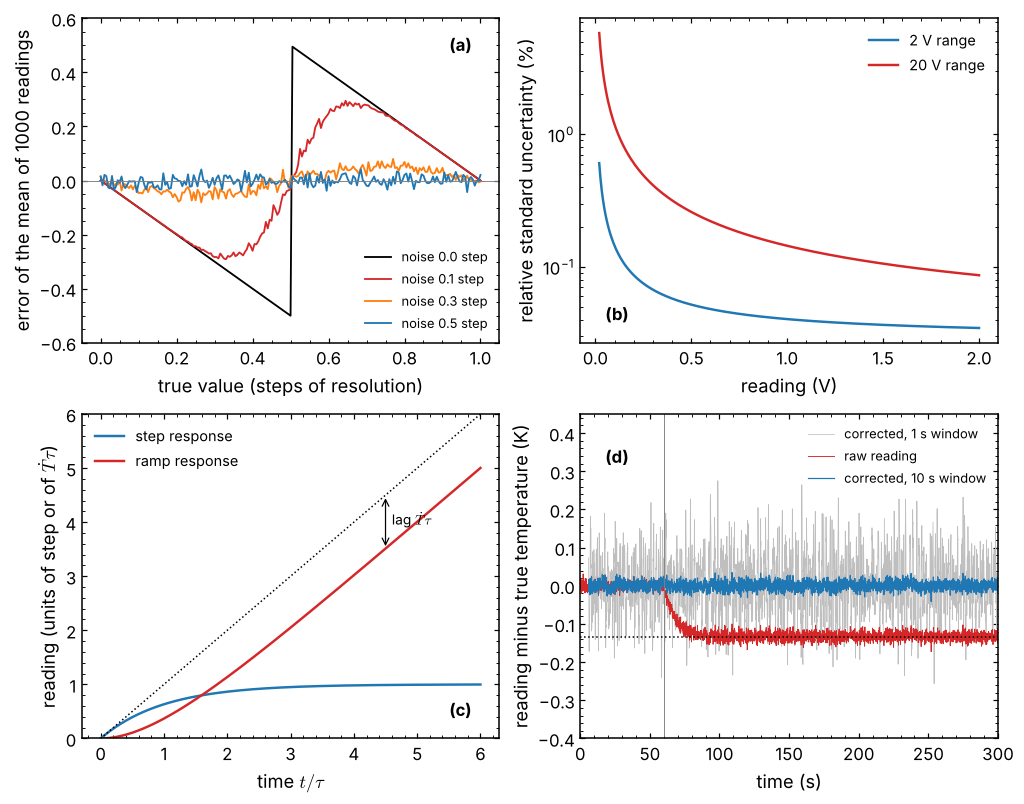

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
for sigma, c in ((0.0, "k"), (0.1, "C3"), (0.3, "C1"), (0.5, "C0")):
    ax.plot(x_true, avg_error[sigma], color=c, lw=1.2, label=f"noise {sigma:.1f} step")
ax.axhline(0, color="0.5", lw=0.6)
ax.set_xlabel("true value (steps of resolution)"); ax.set_ylabel("error of the mean of 1000 readings")
ax.set_ylim(-0.6, 0.6); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.88)

ax = axes[0, 1]
VV = np.linspace(0.02, 2.0, 300)
ax.semilogy(VV, 100 * u_voltmeter(VV, 2.0, 1e-4) / VV, "C0", label="2 V range")
ax.semilogy(VV, 100 * u_voltmeter(VV, 20.0, 1e-3) / VV, "C3", label="20 V range")
ax.set_xlabel("reading (V)"); ax.set_ylabel("relative standard uncertainty (%)")
ax.legend(loc="upper right"); ep.panel_label(ax, "(b)", x=0.06, y=0.12)

ax = axes[1, 0]
ts = np.linspace(0, 6, 300)
ax.plot(ts, 1 - np.exp(-ts), "C0", label="step response")
ax.plot(ts, ts, "k:", lw=1)
ax.plot(ts, ts - 1 + np.exp(-ts), "C3", label="ramp response")
ax.annotate("", (4.5, 3.5), (4.5, 4.5), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax.text(4.6, 3.95, r"lag $\dot T\tau$", fontsize=9)
ax.set_xlabel(r"time $t/\tau$"); ax.set_ylabel("reading (units of step or of $\\dot T\\tau$)")
ax.set_ylim(0, 6); ax.legend(loc="upper left"); ep.panel_label(ax, "(c)", x=0.88, y=0.12)

ax = axes[1, 1]
ax.plot(t[60:-60], (T_corr[11] - T_true)[60:-60], color="0.75", lw=0.5, label="corrected, 1 s window")
ax.plot(t, T_read - T_true, color="C3", lw=0.6, label="raw reading")
ax.plot(t[60:-60], (T_corr[101] - T_true)[60:-60], color="C0", lw=0.8, label="corrected, 10 s window")
ax.axhline(-rate * tau, color="k", ls=":", lw=1)
ax.axvline(60, color="0.5", lw=0.6)
ax.set_xlabel("time (s)"); ax.set_ylabel("reading minus true temperature (K)")
ax.set_xlim(0, 300); ax.set_ylim(-0.4, 0.45)
ax.legend(loc="upper right", fontsize=8.5, framealpha=1); ep.panel_label(ax, "(d)", x=0.06, y=0.9)
plt.show()

**(a)** Error of an average of 1000 readings against the position of the
true value within a resolution step, for several noise levels. **(b)**
Relative uncertainty of a voltmeter reading on two ranges. **(c)** Response
of a first-order instrument to a step and to a ramp (dotted: the true ramp).
**(d)** A thermometer during a heating ramp that starts at 60 s (vertical
line), first 300 s: the raw
reading lags by $\dot T\tau$ (dotted line); the corrected readings are
unbiased on the steady ramp; the 1 s window is much noisier than the 10 s
one.

## Summary

* Every static characteristic of an instrument (resolution, nonlinearity,
  hysteresis, repeatability) belongs in the uncertainty budget.
* Averaging beats the resolution only when the readings scatter over more
  than about half a step; otherwise quote $\delta/\sqrt{12}$.
* Calibration errors are systematic and common to all readings; they cancel
  only in differences and ratios.
* Convert accuracy specifications to standard uncertainties with $\sqrt 3$;
  use the most sensitive range.
* A first-order instrument lags a changing quantity by $\dot T\tau$, a
  systematic error invisible to repetition. Wait $\gtrsim 5\tau$ after a step,
  or correct for the lag, trading noise against time resolution.

## References

* J. P. Bentley, *Principles of Measurement Systems*, 4th ed. (Pearson,
  2005).
* E. O. Doebelin, *Measurement Systems: Application and Design*, 5th ed.
  (McGraw-Hill, 2004).

## Exercises

1. A balance reads to 0.1 g. Ten weighings of a coin all give 7.3 g. State
   the result with its uncertainty, and explain why $s/\sqrt{10}$ is not the
   answer.
2. Show that the ramp lag of a first-order instrument is exactly
   $\dot T\tau$ once transients have decayed.
3. A thermocouple with $\tau = 0.5$ s measures a gas temperature fluctuating
   at 2 Hz with an amplitude of 5 K. What amplitude does it indicate?
4. A pressure gauge is specified as ±0.25 % of full scale, 0 to 10 bar.
   Compare the relative standard uncertainty of readings of 1 bar and 9 bar.
5. In the lag correction, vary the smoothing window $w$. Plot the scatter
   on the steady ramp and the largest error within 40 s of the ramp start against $w$,
   and find the window that minimises the larger of the two.

---

**Previous:** [1. Measurements, errors and how to report a result](01_measurement_and_uncertainty.ipynb) &nbsp;·&nbsp; **Next:** [3. Propagation of uncertainty](03_propagation_of_uncertainty.ipynb)